# Weather uncertainty with real weather data: a sequential stochastic optimization

This notebook applies the approach of
[`weather_sequences_approach.md`](weather_sequences_approach.md) to **real weather data** and runs
it as a **sequential stochastic optimization** (`sequentialStochasticOptimization`): a rolling
horizon whose windows are multi-stage stochastic programs.

* **Weather record:** ERA5 (ERA-NUTS, 1980–2021) as the history, PECD 4.2 projections
  (MPI-ESM1-2-HR, SSP2-4.5, 2022–2050) as the weather that is "realized" over the pathway.
  The PECD 100 m wind speeds are bias-corrected to ERA5 first (section 1).
* **Pathway:** 2026–2050, one investment period per year, two regions (north and south Germany),
  with the existing system as stock and realistic **lead times** that differ between the
  regions. Lead times are certain.
* **Windows:** 15 years, **three stages of five years**. Each window implements its first stage
  (five years) and the next window starts right after it.
* **Tree of a window:** the root holds the realized weather of the first stage. Stage 2 branches
  into representative 5-year weather sequences selected with tsam from all weather years observed
  so far (history plus the years realized by earlier windows). **Stage 3 is selected
  conditionally**: for every stage-2 node, tsam selects again from the observed years extended by
  that node's own sequence, so the stage-3 sequences and their (conditional) probabilities depend
  on the parent's weather.
* **Time series aggregation within the investment periods** uses a coarse raster (6 typical days
  of 6 segments each) to keep the runtime manageable.
* **Evaluation:** the implemented pathway is solved in hindsight with all its decisions fixed, and
  compared with perfect foresight on the same data.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tsam

import fine as fn
from fine.expansionModules import multiStageStochasticProgram as mssp
from fine.expansionModules.sequentialStochasticOptimization import (
    evaluateImplementedPathway,
    realizedValues,
    sequentialStochasticOptimization,
)

WEATHER_DATA = Path("C:/Becker/Data/Weather/data")  # see the README there
REGIONS = ["north", "south"]
HOURS = 8760
REFERENCE_PERIOD = slice("1991", "2021")  # climatology the PECD wind is corrected to
SOLVER = "gurobi"

## 1. Weather data

Both data sets hold hourly regional means for north and south Germany (UTC): 2 m temperature,
10 m and 100 m wind speed and global horizontal irradiance. 29 February is dropped, so that every
weather year has 8760 hours.

**PECD wind is bias-adjusted to the Global Wind Atlas**, which runs higher than raw ERA5. The jump
between 2021 (ERA5) and 2022 (PECD) is therefore not climate change. It is not uniform either: in
the south, the weak-wind quantiles are up to 37 % higher, the mean 23 %. A single scaling factor
would leave the calm hours too windy, so the PECD 100 m wind speed is **quantile-mapped** onto the
ERA5 distribution of 1991–2021, per region and calendar month. This also removes any wind trend
the climate model has; temperature and irradiance (+0.6–0.7 K, +1.5–2.5 %) are kept as they are,
since their changes are plausible climate signals.

PECD 2022-2050 relative to ERA5 1991-2021 (ratios; temperature as difference):


100 m wind, mean  100 m wind, q5  100 m wind, q50  \
north PECD raw                   1.107           1.145            1.084   
      PECD corrected             1.000           0.999            1.000   
south PECD raw                   1.229           1.372            1.200   
      PECD corrected             1.000           1.000            1.000   

                      100 m wind, q95  irradiance, mean  temperature, mean [K]  
north PECD raw                  1.140             1.015                  0.568  
      PECD corrected            1.000             1.015                  0.568  
south PECD raw                  1.244             1.025                  0.743  
      PECD corrected            1.000             1.025                  0.743

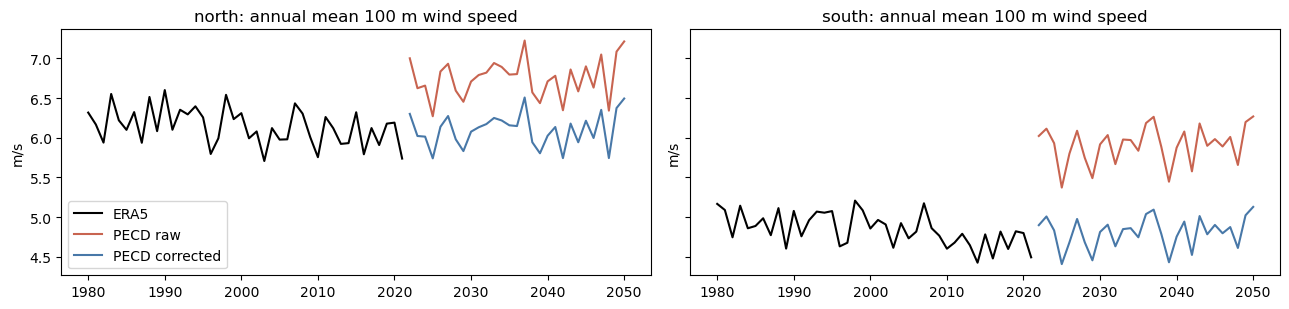

In [2]:
def readRegion(path):
    frame = pd.read_csv(path, index_col=0, parse_dates=True)
    return frame[~((frame.index.month == 2) & (frame.index.day == 29))]


era = {r: readRegion(WEATHER_DATA / "quick" / f"era_nuts_{r}_hourly.csv") for r in REGIONS}
pecdRaw = {
    r: readRegion(
        WEATHER_DATA / "pecd" / "processed" / f"pecd_mpi_esm1_2_hr_ssp2_4_5_{r}_hourly.csv"
    )
    for r in REGIONS
}


def quantileMap(values, months, reference, referenceMonths, points=201):
    # Empirical quantile mapping per calendar month onto the reference distribution
    mapped = np.empty(len(values))
    quantiles = np.linspace(0, 1, points)
    for month in range(1, 13):
        sel = months == month
        source = np.quantile(values[sel], quantiles)
        target = np.quantile(reference[referenceMonths == month], quantiles)
        mapped[sel] = np.interp(values[sel], source, target)
    return mapped


pecd = {}
for r in REGIONS:
    reference = era[r].loc[REFERENCE_PERIOD, "ws100_ms"]
    pecd[r] = pecdRaw[r].assign(
        ws100_ms=quantileMap(
            pecdRaw[r]["ws100_ms"].to_numpy(),
            pecdRaw[r].index.month,
            reference.to_numpy(),
            reference.index.month,
        )
    )

# Bias table: ERA5 climatology vs. PECD before and after the correction
quantiles = [0.05, 0.5, 0.95]
rows = {}
for r in REGIONS:
    reference = era[r].loc[REFERENCE_PERIOD]
    for name, frame in [("PECD raw", pecdRaw[r]), ("PECD corrected", pecd[r])]:
        rows[(r, name)] = {
            "100 m wind, mean": frame["ws100_ms"].mean() / reference["ws100_ms"].mean(),
            **{
                f"100 m wind, q{int(q * 100)}": frame["ws100_ms"].quantile(q)
                / reference["ws100_ms"].quantile(q)
                for q in quantiles
            },
            "irradiance, mean": frame["ghi_Wm2"].mean() / reference["ghi_Wm2"].mean(),
            "temperature, mean [K]": frame["t2m_degC"].mean() - reference["t2m_degC"].mean(),
        }
print("PECD 2022-2050 relative to ERA5 1991-2021 (ratios; temperature as difference):")
display(pd.DataFrame(rows).T.round(3))

# One record of weather years: ERA5 up to 2021, corrected PECD from 2022
weather = {}
for r in REGIONS:
    record = pd.concat([era[r], pecd[r]])
    for year, frame in record.groupby(record.index.year):
        weather.setdefault(year, {})[r] = frame.reset_index(drop=True)
WEATHER_YEARS = sorted(weather)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, r in zip(axes, REGIONS):
    annual = lambda frame: frame["ws100_ms"].groupby(frame.index.year).mean()  # noqa: E731
    ax.plot(annual(era[r]), color="k", label="ERA5")
    ax.plot(annual(pecdRaw[r]), color="#C86450", label="PECD raw")
    ax.plot(annual(pecd[r]), color="#4878A8", label="PECD corrected")
    ax.set_title(f"{r}: annual mean 100 m wind speed")
    ax.set_ylabel("m/s")
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. Capacity factors and demand

**Wind** (onshore): a generic turbine (cut-in 3 m/s, rated 11 m/s, cut-out 25 m/s) at 100 m,
with its power curve smoothed for a fleet (Gaussian with σ = 0.6 + 0.2·u m/s, as in
Renewables.ninja). The data are regional means of the wind speed, which are smoother than the
wind at any single site; the smoothed curve compensates part of that. The speeds are scaled per
region so that the mean capacity factor over 1991–2021 is 0.27 in the north and 0.21 in the
south (new turbines).

**PV:** horizontal irradiance with a simple temperature loss, scaled per region to mean capacity
factors of 0.105 (north) and 0.115 (south) over 1991–2021.

**Demand**, as in the prototype, is built from parts: a base load with a daily and weekly pattern
(in local time), heat pumps driven by the **real** hourly temperature (heating degree hours below
15 °C), data centres and electric vehicles. The parts follow one structural path from 2026 to
2050 (linear); the weather years only change the heat-pump load.

These are deliberately simple conversions. Gridded ERA5 data, converted to capacity factors per
cell before aggregating (see the data README), would be better; the processing scripts exist,
but the gridded data have not been downloaded yet.

Spread over the 71 weather years (1980-2050):


region                           north   south
wind CF                   mean   0.272   0.212
                          min    0.234   0.170
                          max    0.320   0.250
hours wind CF < 0.1 [%]   mean  32.580  45.689
                          min   25.685  37.705
                          max   39.521  53.311
longest calm spell [days] mean   8.761  13.056
                          min    5.000   7.000
                          max   18.000  29.000
PV CF                     mean   0.105   0.115
                          min    0.096   0.106
                          max    0.115   0.129
peak/mean demand (2038)   mean   1.484   1.493
                          min    1.360   1.377
                          max    1.638   1.628

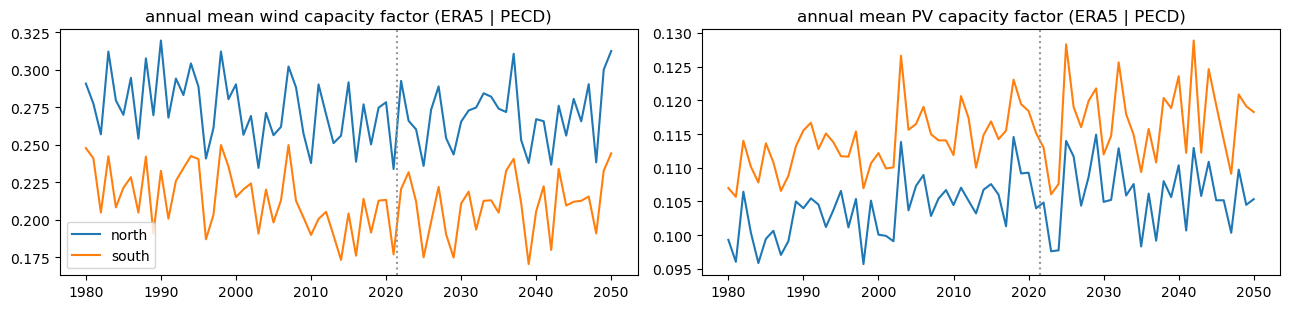

In [3]:
# --- wind: fleet power curve
U_IN, U_RATED, U_OUT = 3.0, 11.0, 25.0
_speeds = np.linspace(0, 40, 4001)
_single = np.clip((_speeds**3 - U_IN**3) / (U_RATED**3 - U_IN**3), 0, 1)
_single[(_speeds < U_IN) | (_speeds >= U_OUT)] = 0.0
CURVE_SPEEDS = np.linspace(0, 40, 801)
CURVE = np.array(
    [
        np.average(_single, weights=np.exp(-0.5 * ((_speeds - u) / (0.6 + 0.2 * u)) ** 2))
        for u in CURVE_SPEEDS
    ]
)


def windCapacityFactor(speed, scale):
    return np.interp(speed * scale, CURVE_SPEEDS, CURVE)


def pvRaw(ghi, temperature):
    cellTemperature = temperature + 0.03 * ghi
    return ghi / 1000.0 * (1 - 0.004 * (cellTemperature - 25))


WIND_TARGET = {"north": 0.27, "south": 0.21}
PV_TARGET = {"north": 0.105, "south": 0.115}
windScale, pvScale = {}, {}
for r in REGIONS:
    reference = era[r].loc[REFERENCE_PERIOD]
    low, high = 0.5, 3.0
    for _ in range(50):  # bisection on the speed scale
        mid = (low + high) / 2
        if windCapacityFactor(reference["ws100_ms"].to_numpy(), mid).mean() < WIND_TARGET[r]:
            low = mid
        else:
            high = mid
    windScale[r] = mid
    pvScale[r] = PV_TARGET[r] / pvRaw(reference["ghi_Wm2"], reference["t2m_degC"]).mean()

cf = {}
for year in WEATHER_YEARS:
    for r in REGIONS:
        w = weather[year][r]
        cf[(year, r, "wind")] = windCapacityFactor(w["ws100_ms"].to_numpy(), windScale[r])
        cf[(year, r, "pv")] = np.clip(
            pvScale[r] * pvRaw(w["ghi_Wm2"].to_numpy(), w["t2m_degC"].to_numpy()), 0, 1
        )


def capacityFactors(kind, weatherYear):
    return pd.DataFrame({r: cf[(weatherYear, r, kind)] for r in REGIONS})


# --- demand
_localHour = (np.arange(HOURS) + 1) % 24  # UTC + 1
_weekday = (np.arange(HOURS) // 24) % 7
BASE_SHAPE = 1 + 0.18 * np.sin(2 * np.pi * (_localHour - 7) / 24) - 0.08 * (_weekday >= 5)
BASE_SHAPE /= BASE_SHAPE.mean()
EV_SHAPE = 0.2 + np.exp(-0.5 * (((_localHour - 20 + 12) % 24) - 12) ** 2 / 9)
EV_SHAPE /= EV_SHAPE.mean()

heatProfile = {
    (year, r): np.clip(15.0 - weather[year][r]["t2m_degC"].to_numpy(), 0, None)
    for year in WEATHER_YEARS
    for r in REGIONS
}
heatNorm = {
    r: np.mean([heatProfile[(y, r)].mean() for y in range(1991, 2022)]) for r in REGIONS
}


def structure(year):
    # Average load per part and region [GW], linear from 2026 to 2050
    x = (year - 2026) / (2050 - 2026)

    def path(start, end):
        return start + (end - start) * x

    return {
        "base": {"north": 27.0, "south": 25.0},
        "heatPump": {"north": path(1.5, 9.0), "south": path(1.5, 9.0)},
        "dataCentre": {"north": path(1.0, 4.0), "south": path(0.8, 3.0)},
        "electricVehicles": {"north": path(1.0, 7.0), "south": path(1.0, 7.0)},
    }


def demand(year, weatherYear):
    # Hourly demand [GW] of pathway year `year` with the weather of `weatherYear`
    s = structure(year)
    return pd.DataFrame(
        {
            r: s["base"][r] * BASE_SHAPE
            + s["heatPump"][r] * heatProfile[(weatherYear, r)] / heatNorm[r]
            + s["dataCentre"][r]
            + s["electricVehicles"][r] * EV_SHAPE
            for r in REGIONS
        }
    )


# Indicators per weather year
rows = {}
for year in WEATHER_YEARS:
    for r in REGIONS:
        wind = cf[(year, r, "wind")]
        daily = wind.reshape(365, 24).mean(axis=1)
        longest = current = 0
        for calm in daily < 0.1:
            current = current + 1 if calm else 0
            longest = max(longest, current)
        d = demand(2038, year)[r]
        rows[(r, year)] = {
            "wind CF": wind.mean(),
            "hours wind CF < 0.1 [%]": 100 * (wind < 0.1).mean(),
            "longest calm spell [days]": longest,
            "PV CF": cf[(year, r, "pv")].mean(),
            "peak/mean demand (2038)": d.max() / d.mean(),
        }
indicators = pd.DataFrame(rows).T
indicators.index.names = ["region", "weather year"]
print("Spread over the 71 weather years (1980-2050):")
display(indicators.groupby(level="region").agg(["mean", "min", "max"]).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for r in REGIONS:
    data = indicators.xs(r, level="region")
    axes[0].plot(data.index, data["wind CF"], label=r)
    axes[1].plot(data.index, data["PV CF"], label=r)
for ax, title in zip(axes, ["wind capacity factor", "PV capacity factor"]):
    ax.axvline(2021.5, color="0.6", ls=":")
    ax.set_title(f"annual mean {title} (ERA5 | PECD)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 3. Selecting weather sequences

The selection works as in the prototype. Candidate sequences are all windows of five consecutive
weather years of a **record**. Every year is compressed to its duration curves (demand, wind,
PV, residual load of a reference fleet, and 7- and 14-day rolling residual load for persistence),
sampled at 365 points. tsam clusters the candidates (hierarchical, medoid, so representatives are
real sequences); the **extreme sequence** (the one with the worst week of residual load) is taken
out before clustering and kept as its own branch. A branch's probability is the share of the
(mildly recency-weighted) candidates in its cluster. Identical candidates are merged and their
weights added.

What is new is the **record** (sequences of consecutive years are labelled `2001-2005`, others
list every year):

* **Stage 2** of the window starting in year *t*: all weather years observed before *t*: ERA5
  1980–2021, PECD 2022–2025, and the PECD years realized by the earlier windows.
* **Stage 3**, below a stage-2 node with sequence *S*: the same record **extended by *S***, as if
  *S* had been observed. The candidates ending in *S*'s years are the most recent ones, so they get
  the highest recency weight, and the stage-3 branches and their **conditional probabilities**
  depend on the parent's weather.

The realized years of the pathway are not in the record before they are realized.

In [4]:
PATHWAY_YEARS = list(range(2026, 2051))
HISTORY = [y for y in WEATHER_YEARS if y < PATHWAY_YEARS[0]]  # observed before the pathway
SEQUENCE_LENGTH = 5  # = investment periods per stage
REPRESENTATIVES = {2: 3, 3: 3}  # per branching, the extreme sequence included
RECENCY_BOOST = 0.5  # the most recent candidate weighs 1 + RECENCY_BOOST times the oldest
CURVE_POINTS = 365

# Features of every weather year, compressed to duration curves
REFERENCE_YEAR = 2038  # demand structure used for selecting
REFERENCE_FLEET = {"wind": {"north": 70.0, "south": 30.0}, "pv": {"north": 70.0, "south": 120.0}}
ranks = np.linspace(0, HOURS - 1, CURVE_POINTS).round().astype(int)
yearCurves = {}
for year in WEATHER_YEARS:
    d = demand(REFERENCE_YEAR, year)
    features = pd.DataFrame(index=range(HOURS))
    residual = 0
    for r in REGIONS:
        features[f"demand_{r}"] = d[r]
        features[f"wind_{r}"] = cf[(year, r, "wind")]
        features[f"pv_{r}"] = cf[(year, r, "pv")]
        residual = (
            residual
            + d[r]
            - REFERENCE_FLEET["wind"][r] * cf[(year, r, "wind")]
            - REFERENCE_FLEET["pv"][r] * cf[(year, r, "pv")]
        )
    features["residualLoad"] = residual
    features["residualLoad_mean7d"] = residual.rolling(168, min_periods=1).mean()
    features["residualLoad_mean14d"] = residual.rolling(336, min_periods=1).mean()
    yearCurves[year] = pd.DataFrame(
        {c: np.sort(features[c].to_numpy())[::-1][ranks] for c in features.columns}
    )
COLUMN_WEIGHTS = {c: 1.0 for c in yearCurves[WEATHER_YEARS[0]].columns}
COLUMN_WEIGHTS.update({"residualLoad": 3.0, "residualLoad_mean7d": 3.0, "residualLoad_mean14d": 2.0})


def selectSequences(record, length, representatives):
    # Representative sequences of `length` consecutive years of `record`, as a list of
    # (sequence, probability, kind), the extreme sequence last.
    span = max(len(record) - length, 1)
    weights = {}
    for start in range(len(record) - length + 1):
        sequence = tuple(record[start : start + length])
        weights[sequence] = weights.get(sequence, 0.0) + 1 + RECENCY_BOOST * start / span
    candidates = list(weights)
    worstWeek = {
        seq: max(yearCurves[y]["residualLoad_mean7d"].max() for y in seq) for seq in candidates
    }
    extreme = max(worstWeek, key=worstWeek.get)
    regular = [seq for seq in candidates if seq != extreme]
    stacked = pd.concat([yearCurves[y] for seq in regular for y in seq], ignore_index=True)
    stacked.index = pd.date_range("2001-01-01", periods=len(stacked), freq="h")
    selection = tsam.aggregate(
        stacked,
        representatives - 1,
        period_duration=length * CURVE_POINTS,  # one "period" = one whole sequence
        cluster=tsam.ClusterConfig(method="hierarchical", representation="medoid"),
        weights=COLUMN_WEIGHTS,
        preserve_column_means=False,
    )
    total = sum(weights.values())
    assignments = np.asarray(selection.cluster_assignments)
    result = []
    for cluster in sorted(set(assignments)):
        members = [regular[i] for i in np.flatnonzero(assignments == cluster)]
        representative = np.asarray(selection.cluster_representatives.loc[cluster])
        deviation = {
            m: np.abs(
                pd.concat([yearCurves[y] for y in m], ignore_index=True).to_numpy()
                - representative
            ).max()
            for m in members
        }
        medoid = min(deviation, key=deviation.get)
        result.append((medoid, sum(weights[m] for m in members) / total, "regular"))
    result.append((extreme, weights[extreme] / total, "extreme"))
    return result


def sequenceLabel(sequence):
    # "2001-2005" for consecutive years, else every year (e.g. a candidate that starts with
    # a realized year and continues with the parent node's sequence)
    if list(sequence) == list(range(sequence[0], sequence[0] + len(sequence))):
        return f"{sequence[0]}-{sequence[-1]}"
    return ",".join(str(y) for y in sequence)


def showSelection(selection):
    return pd.DataFrame(
        [{"sequence": sequenceLabel(s), "probability": p, "kind": k} for s, p, k in selection]
    ).round(3)


# Demonstration for the first window (2026-2040)
start = time.time()
stage2 = selectSequences(HISTORY, SEQUENCE_LENGTH, REPRESENTATIVES[2])
print(f"Stage 2 of the first window, from {HISTORY[0]}-{HISTORY[-1]} ({time.time() - start:.1f} s):")
display(showSelection(stage2))
for sequence, probability, kind in stage2:
    conditional = selectSequences(HISTORY + list(sequence), SEQUENCE_LENGTH, REPRESENTATIVES[3])
    print(f"Stage 3 below {sequenceLabel(sequence)} (conditional probabilities):")
    display(showSelection(conditional))

Stage 2 of the first window, from 1980-2025 (4.6 s):


,sequence,probability,kind
0,2001-2005,0.754,regular
1,2013-2017,0.224,regular
2,1993-1997,0.022,extreme


Stage 3 below 2001-2005 (conditional probabilities):


,sequence,probability,kind
0,2001-2005,0.758,regular
1,2011-2015,0.223,regular
2,1993-1997,0.019,extreme


Stage 3 below 2013-2017 (conditional probabilities):


,sequence,probability,kind
0,2001-2005,0.799,regular
1,2012-2016,0.182,regular
2,1993-1997,0.019,extreme


Stage 3 below 1993-1997 (conditional probabilities):


,sequence,probability,kind
0,2001-2005,0.719,regular
1,2012-2016,0.236,regular
2,1993-1997,0.045,extreme


## 4. The model

One investment period per year, 2026–2050, 8760 hours per year, two regions. The pathway model
holds the **realized** data: the corrected PECD weather of the year itself. A window's tree
replaces them with the weather of its nodes, except in the root.

| component | invest [bn EUR/GW(h)] | lifetime | lead time north / south | stock (spread over) |
|---|---|---|---|---|
| Wind (onshore) | 1.40 | 25 a | 3 / 2 a | 50 / 15 GW (2001–2025) |
| PV | 0.65 | 25 a | 1 / 2 a | 40 / 70 GW (2010–2025) |
| Gas turbine (firm capacity, 45 %) | 0.80 | 30 a | 4 / 5 a | 40 / 40 GW (1996–2025) |
| Battery (4 h) | 0.25 per GWh | 15 a | 1 / 1 a | – |
| Grid north–south (400 km) | 0.0015 per GW·km | 40 a | 8 a | 12 GW (2000) |

Fuel and CO₂ cost 60 EUR/MWh of gas, load shedding 10,000 EUR/MWh, interest rate 5 %. The stock
stands for the existing system (the gas turbines for all firm thermal capacity) and retires with
its technical lifetime, so the pathway has to replace it, with the lead times in the way.

**Windows of 15 years for lifetimes of 25–40 years** are enough here: FINE books investments as
annuities, so each year of a window weighs one year's annuity against that year's benefit, and a
plant does not need to pay off within the window. What the window has to cover is the lead time
plus enough operating years to see the benefit: a decision in the last year of stage 1 is
available after at most five years (eight for the grid), leaving five or more operating years in
the window.

In [5]:
LEAD_TIMES = {
    "Wind": pd.Series({"north": 3, "south": 2}),
    "PV": pd.Series({"north": 1, "south": 2}),
    "GasTurbine": pd.Series({"north": 4, "south": 5}),
    "Battery": pd.Series({"north": 1, "south": 1}),
    "Grid": 8,
}


def spreadStock(total, firstYear, lastYear):
    years = range(firstYear, lastYear + 1)
    return {y: pd.Series({r: total[r] / len(years) for r in REGIONS}) for y in years}


def buildPathwayModel(years, weatherOfYear=None):
    # Pathway model over `years`; weatherOfYear maps a pathway year to its weather year
    # (default: the year itself, i.e. the realized PECD weather)
    weatherOfYear = weatherOfYear or {y: y for y in years}
    esM = fn.EnergySystemModel(
        locations=set(REGIONS),
        commodities={"electricity", "naturalGas"},
        numberOfTimeSteps=HOURS,
        commodityUnitsDict={"electricity": "GW_el", "naturalGas": "GW_CH4"},
        hoursPerTimeStep=1,
        costUnit="1e9 Euro",
        startYear=years[0],
        numberOfInvestmentPeriods=len(years),
        investmentPeriodInterval=1,
        lengthUnit="km",
        verboseLogLevel=2,
    )
    esM.add(fn.Source(esM, name="Wind", commodity="electricity", hasCapacityVariable=True,
                      operationRateMax={y: capacityFactors("wind", weatherOfYear[y]) for y in years},
                      capacityMax=pd.Series({"north": 140.0, "south": 80.0}),
                      investPerCapacity=1.4, opexPerCapacity=1.4 * 0.025, interestRate=0.05,
                      economicLifetime=25, technicalLifetime=25, leadTime=LEAD_TIMES["Wind"],
                      stockCommissioning=spreadStock({"north": 50.0, "south": 15.0}, 2001, 2025)))
    esM.add(fn.Source(esM, name="PV", commodity="electricity", hasCapacityVariable=True,
                      operationRateMax={y: capacityFactors("pv", weatherOfYear[y]) for y in years},
                      capacityMax=pd.Series({"north": 200.0, "south": 300.0}),
                      investPerCapacity=0.65, opexPerCapacity=0.65 * 0.015, interestRate=0.05,
                      economicLifetime=25, technicalLifetime=25, leadTime=LEAD_TIMES["PV"],
                      stockCommissioning=spreadStock({"north": 40.0, "south": 70.0}, 2010, 2025)))
    esM.add(fn.Source(esM, name="GasPurchase", commodity="naturalGas",
                      hasCapacityVariable=False, commodityCost=60e-6))  # 60 EUR/MWh incl. CO2
    esM.add(fn.Source(esM, name="LoadShedding", commodity="electricity",
                      hasCapacityVariable=False, commodityCost=10e-3))  # 10,000 EUR/MWh
    esM.add(fn.Conversion(esM, name="GasTurbine", physicalUnit="GW_el",
                          commodityConversionFactors={"naturalGas": -1 / 0.45, "electricity": 1.0},
                          hasCapacityVariable=True, investPerCapacity=0.8,
                          opexPerCapacity=0.8 * 0.03, interestRate=0.05, economicLifetime=30,
                          technicalLifetime=30, leadTime=LEAD_TIMES["GasTurbine"],
                          stockCommissioning=spreadStock({"north": 40.0, "south": 40.0}, 1996, 2025)))
    esM.add(fn.Storage(esM, name="Battery", commodity="electricity", hasCapacityVariable=True,
                       chargeRate=0.25, dischargeRate=0.25, chargeEfficiency=0.95,
                       dischargeEfficiency=0.95, investPerCapacity=0.25,
                       opexPerCapacity=0.25 * 0.01, interestRate=0.05, economicLifetime=15,
                       technicalLifetime=15, leadTime=LEAD_TIMES["Battery"]))
    esM.add(fn.Transmission(esM, name="Grid", commodity="electricity", hasCapacityVariable=True,
                            distances=pd.DataFrame([[0, 400], [400, 0]], index=REGIONS, columns=REGIONS),
                            losses=0.00005, investPerCapacity=0.0015, interestRate=0.05,
                            economicLifetime=40, technicalLifetime=40, leadTime=LEAD_TIMES["Grid"],
                            stockCommissioning={2000: pd.Series({"north_south": 12.0, "south_north": 12.0})}))
    esM.add(fn.Sink(esM, name="Demand", commodity="electricity", hasCapacityVariable=False,
                    operationRateFix={y: demand(y, weatherOfYear[y]) for y in years}))
    return esM


start = time.time()
pathway = buildPathwayModel(PATHWAY_YEARS)
print(f"pathway model 2026-2050 built in {time.time() - start:.0f} s")

C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1997. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1998. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1999. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2000. It will be rounded to 10 d

pathway model 2026-2050 built in 1 s


## 5. The tree of a window

`buildWeatherTree` is the `buildTree` function of `sequentialStochasticOptimization`. It is called
for every window with the window's model (holding the realized data), its years, the years of
its stages and the years realized so far.

* **Root:** the realized weather of the first stage, read from the window's model with
  `realizedValues`. The first-stage decisions therefore know their own five years of weather
  (a known property of the approach, see the approach note).
* **Stage 2:** one node per representative sequence of the record observed before the window.
* **Stage 3:** below every stage-2 node, one node per representative sequence of the record
  extended by that node's sequence, with conditional probabilities.

The uncertain values of a node are the wind and PV capacity factors and the demand of its years,
always from the **same** weather year. With 3 × 3 representatives, a window has 9 scenarios.

In [1]:
UNCERTAIN = {"Wind": ["operationRateMax"], "PV": ["operationRateMax"], "Demand": ["operationRateFix"]}
selections = {}  # the selected sequences of every window, for the results


def nodeValues(stageYears, sequence):
    pairs = list(zip(stageYears, sequence))
    return {
        "Wind": {"operationRateMax": {y: capacityFactors("wind", w) for y, w in pairs}},
        "PV": {"operationRateMax": {y: capacityFactors("pv", w) for y, w in pairs}},
        "Demand": {"operationRateFix": {y: demand(y, w) for y, w in pairs}},
    }


def mostProbable(selection):
    sequence, _, kind = max(selection, key=lambda item: item[1])
    return [(sequence, 1.0, kind)]


def buildWeatherTree(windowEsM, windowYears, stageYears, realizedYears, deterministic):
    observed = HISTORY + list(realizedYears)
    tree = {"root": {"values": realizedValues(windowEsM, UNCERTAIN, stageYears[0])}}
    record = {"stage2": {}, "stage3": {}}
    stage2 = selectSequences(observed, len(stageYears[1]), REPRESENTATIVES[2])
    for i, (sequence2, p2, kind2) in enumerate(mostProbable(stage2) if deterministic else stage2):
        node2 = f"S{i + 1}:{sequenceLabel(sequence2)}"
        record["stage2"][node2] = (sequence2, p2, kind2)
        tree[node2] = {"parent": "root", "probability": p2,
                       "values": nodeValues(stageYears[1], sequence2)}
        if len(stageYears) < 3:
            continue
        stage3 = selectSequences(observed + list(sequence2), len(stageYears[2]), REPRESENTATIVES[3])
        record["stage3"][node2] = mostProbable(stage3) if deterministic else stage3
        for j, (sequence3, p3, _) in enumerate(record["stage3"][node2]):
            tree[f"{node2}/{j + 1}:{sequenceLabel(sequence3)}"] = {
                "parent": node2, "probability": p3, "values": nodeValues(stageYears[2], sequence3)}
    selections[windowYears[0]] = record
    return tree

## 6. Sequential stochastic optimization

Three windows, 2026–2040, 2031–2045 and 2036–2050, each implementing its first five years. The
data end in 2050, so with `endOfHorizon="extend"` the implemented pathway ends in 2040 (the last
window looks ten years beyond it). Every window is solved as one extensive form with Gurobi.

**Time series aggregation within an investment period** (per scenario and year): 6 typical days
of 6 segments (4 h on average), with the days of peak demand in both regions kept
(`method="replace"`, so every year has the same number of typical days). This is coarse:
it smooths out short shortages, so the need for firm capacity is underestimated somewhat.

In [7]:
WINDOW_LENGTH = 15
STAGES = [list(range(s * SEQUENCE_LENGTH, (s + 1) * SEQUENCE_LENGTH)) for s in range(3)]
LAST_YEAR = 2040
AGGREGATION = {
    "n_clusters": 6,
    "period_duration": 24,
    "segments": tsam.SegmentConfig(n_segments=6),
    "extremes": tsam.ExtremeConfig(
        method="replace",
        max_value=["Demand_operationRateFix_north", "Demand_operationRateFix_south"],
    ),
}

start = time.time()
results = sequentialStochasticOptimization(
    pathway,
    windowLength=WINDOW_LENGTH,
    stageInvestmentPeriods=STAGES,
    buildTree=buildWeatherTree,
    lastYear=LAST_YEAR,
    endOfHorizon="extend",
    msspSettings={
        "method": "ef",
        "solver": SOLVER,
        "timeSeriesAggregation": True,
        "temporalAggregationSpecs": AGGREGATION,
    },
)
runtime = time.time() - start
print(f"{len(results.windows)} windows solved in {runtime / 60:.1f} min")
for window in results.windows:
    print(f"window {window.years[0]}-{window.years[-1]}: expected NPV {window.objectiveValue:.1f} "
          f"bn EUR, implemented {window.implementedYears[0]}-{window.implementedYears[-1]}")

C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1997. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1998. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1999. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2000. It will be rounded to 10 d

[    0.00] Initializing mpi-sppy
[    0.11] Initializing SPBase


C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2002. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2003. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2004. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2005. It will be rounded to 10 d

[  302.62] Initializing SPBase


C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2007. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2008. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2009. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2010. It will be rounded to 10 d

[  565.23] Initializing SPBase


3 windows solved in 14.2 min
window 2026-2040: expected NPV 659.0 bn EUR, implemented 2026-2030
window 2031-2045: expected NPV 710.9 bn EUR, implemented 2031-2035
window 2036-2050: expected NPV 774.8 bn EUR, implemented 2036-2040


## 7. The trees of the windows

The selected sequences per window, with their probabilities. The stage-3 probabilities are
conditional on the stage-2 node.

In [8]:
rows = []
for windowStart, record in selections.items():
    for node2, (sequence2, p2, kind2) in record["stage2"].items():
        for sequence3, p3, kind3 in record["stage3"][node2]:
            rows.append({
                "window": windowStart,
                "stage 2": f"{sequenceLabel(sequence2)} ({kind2})",
                "p stage 2": p2,
                "stage 3": f"{sequenceLabel(sequence3)} ({kind3})",
                "p stage 3 | stage 2": p3,
                "p scenario": p2 * p3,
            })
display(pd.DataFrame(rows).set_index(["window", "stage 2", "stage 3"]).round(3))
print(results.windows[0].tree.describe())

p stage 2  \
window stage 2             stage 3                                         
2026   2001-2005 (regular) 2001-2005 (regular)                     0.754   
                           2011-2015 (regular)                     0.754   
                           1993-1997 (extreme)                     0.754   
       2013-2017 (regular) 2001-2005 (regular)                     0.224   
                           2012-2016 (regular)                     0.224   
                           1993-1997 (extreme)                     0.224   
       1993-1997 (extreme) 2001-2005 (regular)                     0.022   
                           2012-2016 (regular)                     0.022   
                           1993-1997 (extreme)                     0.022   
2031   2000-2004 (regular) 2030,2000,2001,2002,2003 (regular)      0.422   
                           2027,2028,2029,2030,2000 (regular)      0.422   
                           1993-1997 (extreme)                     0.422   
       2001-2005 (regular) 2030,2001,2002,2003,2004 (regular)      0.558   
                           1991-1995 (regular)                     0.558   
                           1993-1997 (extreme)                     0.558   
       1993-1997 (extreme) 2001-2005 (regular)                     0.019   
                           2002-2006 (regular)                     0.019   
                           1993-1997 (extreme)                     0.019   
2036   2011-2015 (regular) 2000-2004 (regular)                     0.550   
                           2001-2005 (regular)                     0.550   
                           1993-1997 (extreme)                     0.550   
       2001-2005 (regular) 2001-2005 (regular)                     0.433   
                           2000-2004 (regular)                     0.433   
                           1993-1997 (extreme)                     0.433   
       1993-1997 (extreme) 1997-2001 (regular)                     0.017   
                           2011-2015 (regular)                     0.017   
                           1993-1997 (extreme)                     0.017   

                                                               p stage 3 | stage 2  \
window stage 2             stage 3                                                   
2026   2001-2005 (regular) 2001-2005 (regular)                               0.758   
                           2011-2015 (regular)                               0.223   
                           1993-1997 (extreme)                               0.019   
       2013-2017 (regular) 2001-2005 (regular)                               0.799   
                           2012-2016 (regular)                               0.182   
                           1993-1997 (extreme)                               0.019   
       1993-1997 (extreme) 2001-2005 (regular)                               0.719   
                           2012-2016 (regular)                               0.236   
                           1993-1997 (extreme)                               0.045   
2031   2000-2004 (regular) 2030,2000,2001,2002,2003 (regular)                0.672   
                           2027,2028,2029,2030,2000 (regular)                0.311   
                           1993-1997 (extreme)                               0.017   
       2001-2005 (regular) 2030,2001,2002,2003,2004 (regular)                0.800   
                           1991-1995 (regular)                               0.183   
                           1993-1997 (extreme)                               0.017   
       1993-1997 (extreme) 2001-2005 (regular)                               0.727   
                           2002-2006 (regular)                               0.233   
                           1993-1997 (extreme)                               0.040   
2036   2011-2015 (regular) 2000-2004 (regular)                               0.431   
                           2001-2005 (regular)      

Scenario tree with 3 stages, 13 nodes and 9 scenarios:
  stage  1  root                 parent=-                    p=1.0000  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S1:2001-2005         parent=root                 p=0.7538  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S2:2013-2017         parent=root                 p=0.2242  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  2  S3:1993-1997         parent=root                 p=0.0221  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  3  S1:2001-2005/1:2001-2005 parent=S1:2001-2005         p=0.7578  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  3  S1:2001-2005/2:2011-2015 parent=S1:2001-2005         p=0.2228  values=['Demand.operationRateFix', 'PV.operationRateMax', 'Wind.operationRateMax']
  stage  3  S

## 8. The implemented pathway

Capacity commissioned per year (summed over the regions; the grid counted once per line), as
implemented by the windows, and the capacity available in every year of the hindsight evaluation
(section 9), which includes the stock and the lead times.

In [9]:
table = results.implementedCommissioningTable()
oneWay = ~table.index.get_level_values("location").str.endswith("_north")  # grid once per line
added = table[oneWay].groupby(level="component").sum().round(2)
display(added)

byRegion = table[oneWay].groupby(level=["component", "location"]).sum().sum(axis=1).unstack()
print("Total commissioning 2026-2040 [GW, battery GWh]:")
display(byRegion.round(1))

year,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036,2037,2038,2039,2040
component,,,,,,,,,,,,,,,
Battery,0.00,0.0,3.97,0.00,19.44,44.63,0.00,0.00,0.00,0.00,1.86,0.00,0.00,0.00,0.0
GasTurbine,0.00,0.0,9.02,10.34,0.42,1.68,3.01,3.64,13.11,2.89,2.72,8.14,3.82,6.44,0.0
Grid,0.00,0.0,0.00,0.00,0.00,0.00,3.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
PV,57.06,0.0,0.00,0.00,0.00,28.71,0.00,0.00,0.00,0.00,54.34,0.00,0.00,0.00,0.0
Wind,50.81,0.0,4.65,0.00,0.00,22.88,0.30,0.00,0.00,0.00,27.71,0.00,5.41,0.00,0.0


Total commissioning 2026-2040 [GW, battery GWh]:


location,north,north_south,south
component,,,
Battery,37.5,NaN,32.4
GasTurbine,30.6,NaN,34.6
Grid,NaN,3.6,NaN
PV,67.7,NaN,72.4
Wind,69.6,NaN,42.2


## 9. Hindsight evaluation and perfect foresight

`evaluateImplementedPathway` solves 2026–2040 with the realized weather and all commissioning
fixed to the implemented decisions, at a finer time resolution (24 typical days of 24 hours,
peak-demand days kept). Its objective is the cost of the implemented pathway in hindsight.

For comparison, two **perfect foresight** runs: one model over 2026–2050 with the realized
weather (so it also sees the ten years beyond 2040), whose decisions up to 2040 are evaluated in
exactly the same way.

* **coarse:** with the coarse aggregation of the windows. It decides at the same resolution as
  the windows, so the difference to the sequential stochastic run is the effect of deciding
  under weather uncertainty (with the lead times), not of the resolution.
* **fine:** with the evaluation's aggregation. It is (up to the cut at 2040) the best pathway the
  evaluation can see, i.e. the lower bound of the comparison.

Load shedding is shown per year: in 2026 no new capacity can arrive yet (all lead times are at
least one year), and until about 2030 only the components with short lead times can, so that
part of it is the same for every strategy.

C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1997. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1998. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 1999. It will be rounded to 10 digits to check if the installed stock capacity does not exceed capacityMax and capacityFix
  warnings.warn(
C:\Users\j.becker\FINE\fine\utils.py:2477: UserWarning: A stock comissioning of 1.3333333333333333 was passed for location north in year 2000. It will be rounded to 10 d

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter LogToConsole to value 0


...

,"cost 2026-2040 [bn EUR, NPV]",load shedding 2026-2040 [TWh],of it 2026-2030 [TWh]
sequential stochastic,692.48,7.29,0.15
"perfect foresight, coarse",699.69,12.46,0.04
"perfect foresight, fine",648.09,0.05,0.00


Load shedding per year [TWh]:


,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036,2037,2038,2039,2040
sequential stochastic,0.0,0.0,0.04,0.0,0.12,0.42,2.03,0.0,0.00,0.01,0.0,2.35,0.58,1.03,0.72
"perfect foresight, coarse",0.0,0.0,0.04,0.0,0.00,0.17,0.80,0.2,0.64,1.31,0.0,0.57,1.17,7.23,0.34
"perfect foresight, fine",0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.0,0.01,0.03,0.0,0.00,0.00,0.00,0.01


Total commissioning 2026-2040 [GW, battery GWh]:


sequential stochastic  perfect foresight, coarse  \
Battery    north                         37.5                       30.0   
           south                         32.4                       15.2   
GasTurbine north                         30.6                       33.0   
           south                         34.6                       35.6   
Grid       north_south                    3.6                        4.6   
PV         north                         67.7                       50.4   
           south                         72.4                       49.6   
Wind       north                         69.6                       58.3   
           south                         42.2                       35.1   

                        perfect foresight, fine  
Battery    north                           30.1  
           south                           27.3  
GasTurbine north                           39.7  
           south                           40.1  
Grid       north_south                      2.4  
PV         north                           48.3  
           south                           44.8  
Wind       north                           46.7  
           south                           21.2

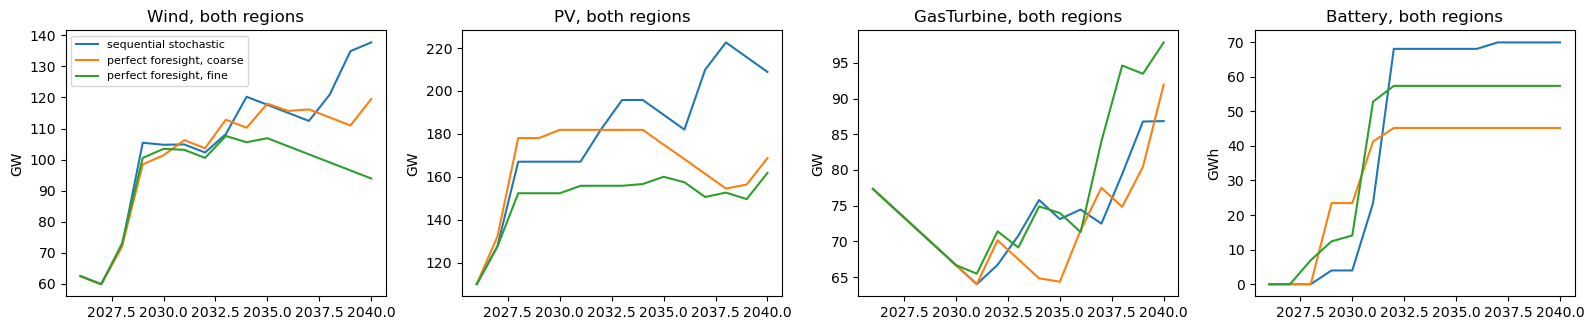

In [10]:
EVALUATION_AGGREGATION = {
    "n_clusters": 24,
    "period_duration": 24,
    "segments": None,
    "extremes": AGGREGATION["extremes"],
}

def commissioningOf(esM, lastYear):
    # {(modelingClass, component, location, year): value} of a solved model, up to lastYear
    commissioning = {}
    for modelingClass, mdl in esM.componentModelingDict.items():
        variable = getattr(esM.pyM, "commis_" + mdl.abbrvName, None)
        if variable is None:
            continue
        for (loc, comp, ip), data in variable.items():
            if ip in esM.investmentPeriods and esM.investmentPeriodNames[ip] <= lastYear:
                commissioning[(modelingClass, comp, loc, esM.investmentPeriodNames[ip])] = data.value
    return commissioning


strategies = {"sequential stochastic": results.implementedCommissioning}
for label, aggregation in [("perfect foresight, coarse", AGGREGATION),
                           ("perfect foresight, fine", EVALUATION_AGGREGATION)]:
    start = time.time()
    perfectForesight = buildPathwayModel(PATHWAY_YEARS)
    perfectForesight.aggregateTemporally(**aggregation)
    perfectForesight.optimize(timeSeriesAggregation=True, solver=SOLVER)
    strategies[label] = commissioningOf(perfectForesight, LAST_YEAR)
    print(f"{label} solved in {time.time() - start:.0f} s")

evaluations = {}
for label, decisions in strategies.items():
    start = time.time()
    evaluations[label] = evaluateImplementedPathway(
        pathway,
        decisions,
        solver=SOLVER,
        timeSeriesAggregation=True,
        temporalAggregationSpecs=EVALUATION_AGGREGATION,
    )
    print(f"{label}: evaluated in {time.time() - start:.0f} s")


def loadSheddingPerYear(esM):
    # Load shedding [TWh] per year, weighted with the typical-day occurrences
    op = esM.pyM.op_srcSnk
    perYear = pd.Series(0.0, index=esM.investmentPeriodNames)
    for key in op:
        if key[1] == "LoadShedding":
            perYear[esM.investmentPeriodNames[key[2]]] += (
                op[key].value * esM.periodOccurrences[key[2]][key[3]] / 1000
            )
    return perYear


shedding = pd.DataFrame({label: loadSheddingPerYear(esM) for label, esM in evaluations.items()})
summary = pd.DataFrame(
    {
        "cost 2026-2040 [bn EUR, NPV]": {label: esM.objectiveValue for label, esM in evaluations.items()},
        "load shedding 2026-2040 [TWh]": shedding.sum(),
        "of it 2026-2030 [TWh]": shedding.loc[:2030].sum(),
    }
)
display(summary.round(2))
print("Load shedding per year [TWh]:")
display(shedding.T.round(2))

totals = {}
for label, decisions in strategies.items():
    series = pd.Series(decisions, dtype=float)
    series = series[~series.index.get_level_values(2).str.endswith("_north")]  # grid once per line
    totals[label] = series.groupby(level=[1, 2]).sum()
print("Total commissioning 2026-2040 [GW, battery GWh]:")
display(pd.DataFrame(totals).round(1))

# Capacity available per year in the evaluations (stock included, lead times applied)
components = ["Wind", "PV", "GasTurbine", "Battery"]
fig, axes = plt.subplots(1, len(components), figsize=(16, 3.4))
for ax, comp in zip(axes, components):
    for label, esM in evaluations.items():
        mdl = esM.componentModelingDict[esM.componentNames[comp]]
        cap = getattr(esM.pyM, "cap_" + mdl.abbrvName)
        perYear = pd.Series(0.0, index=esM.investmentPeriodNames)
        for (loc, name, ip), data in cap.items():
            if name == comp and ip in esM.investmentPeriods:
                perYear[esM.investmentPeriodNames[ip]] += data.value
        ax.plot(perYear.index, perYear.values, label=label)
    ax.set_title(f"{comp}, both regions")
    ax.set_ylabel("GWh" if comp == "Battery" else "GW")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Takeaways

Results of this run (Gurobi, 22 min in total; the three windows took 14 min, about 5 min each
for 9 scenarios × 15 years):

* **Weather data.** After the quantile mapping, the PECD wind matches ERA5 in mean and quantiles
  (section 1). The capacity factors look realistic: 33 % (north) and 46 % (south) of the hours
  have wind CF < 0.1, with calm spells of up to 18 and 29 days (the synthetic prototype data had
  4–10 % of hours below 0.1).
* **Trees.** In every window one sequence dominates stage 2 (probability 0.42–0.75), and the
  extreme sequence is always 1993–1997 with about 0.02. The two regular representatives are
  sometimes almost the same sequence (2000–2004 and 2001–2005 in the 2031 window): averaged over
  five years, the candidate sequences differ little, and two regular clusters carry little
  diversity.
* **Conditional stage 3.** The parent's sequence changes the stage-3 branches and their
  probabilities, but moderately: below the extreme stage-2 node, the extreme stage-3 branch gets
  0.040–0.045 instead of about 0.02. In the 2031 window, the most probable stage-3 sequences
  start with the realized year 2030 and continue with the parent's years
  (2030,2000,2001,2002,2003): candidates spanning the end of the observed record and the appended
  parent sequence. They are consistent with treating the parent's sequence as observed, but they
  repeat four of the parent's five weather years.
* **Decisions are lumpy.** Each window builds almost everything in its first year (2026, 2031,
  2036): with lead times, the earliest decision gives the earliest availability, and the later
  first-stage years only add gas turbines.
* **Hindsight evaluation** (24 hourly typical days, 2026–2040):

  | | cost [bn EUR] | load shedding [TWh] |
  |---|---|---|
  | perfect foresight, fine | 648.1 | 0.05 |
  | sequential stochastic | 692.5 (+6.9 %) | 7.3 |
  | perfect foresight, coarse | 699.7 (+8.0 %) | 12.5 |

  **The coarse raster dominates the result.** Both pathways decided with 6 typical days of
  6 segments shed load in the evaluation, mostly in 2031–2040, not in the early years where the
  lead times bind. With the coarse raster, the models see too little scarcity and build too few
  gas turbines (64–69 GW against 80 GW with the fine raster). The sequential stochastic run is
  cheaper than perfect foresight with the same raster: hedging against nine weather scenarios
  builds more wind, PV and batteries, which partly makes up for the coarse resolution. The value
  of the stochastic approach is therefore confounded with the resolution in this run, and the
  effect of the lead times is not isolated yet.

**Next steps:** a time raster that keeps scarcity (more typical days, or an additional extreme
criterion for the period of lowest wind, which `method="replace"` allows without changing the
number of typical days); a sequential run with a single-path tree (most probable sequences) to
isolate the value of branching; runs without lead times; more representatives per branching;
several realized weather trajectories (other PECD climate models).

Limitations: regional mean wind speeds instead of gridded data; one climate model; synthetic
demand shape (only the heat-pump load follows the real temperature); the stock is a stylized
version of the German system; lead times are certain.
